# 06 · Two-stage recommendation: candidate generation + learning-to-rank

**Learning objectives**

1. Explain why industrial recommenders split **retrieval** from **ranking**.
2. Measure **candidate recall**: the ceiling a ranker can never exceed.
3. Build ranking features and train a gradient-boosted ranker **without leaking the test period**.
4. Interpret the ranker with **permutation importance**.

```
                         ┌─ item-kNN  top-50 ─┐
  user history ──────────┼─ ALS       top-50 ─┼──▶ union (~100–200 items) ──▶ features ──▶ GBDT ranker ──▶ top-10
                         ├─ popularity top-50 ─┤
                         └─ trending  top-50 ─┘
       stage 1: cheap, high recall                                             stage 2: expensive, high precision
```

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_or_synthesize
from recsys.pipeline import prepare_data
from recsys.metrics import evaluate_many
from recsys.models import (ALSRecommender, ItemKNNRecommender, PopularityRecommender,
                           TrendingRecommender, TwoStageRecommender)
from recsys.models.two_stage import generate_candidates, FeatureContext
from recsys.plotting import set_style, PALETTE, model_color, bar_leaderboard

set_style()
events, item_categories, SOURCE = load_or_synthesize()
data = prepare_data(events)
val = prepare_data(events[events["timestamp"] < data.cutoff])

  USING SYNTHETIC DATA: data/raw/events.csv was not found.
  The numbers below come from a simulator, NOT from RetailRocket.
  Run `make data` (needs a Kaggle API token) to use the real dataset.


## 1. Why two stages?

* **Scale.** Scoring every item with a rich model is too slow when there are 100k+ items. Cheap retrieval cuts the problem to a few hundred.
* **Complementary signals.** Each generator is good at something different. The ranker learns *when to trust which*: kNN for users with clear intent, trending for users with thin history, and so on.
* **Features.** The ranker can use any signal: recency, popularity, category affinity, and later price, stock or context. You cannot easily force those into a factorisation.

## 2. Stage 1: how good is the shortlist?

The ranker can only reorder what the generators propose. **Candidate recall@N** (the share of relevant items that make it into the shortlist) is therefore a hard ceiling on the whole system. Let's measure it per generator and for the union, on validation.

In [2]:
fit_kw = dict(train_events=val.train_events, item_map=val.item_map)
gens = {
    "item_knn": ItemKNNRecommender().fit(val.X_train),
    "als": ALSRecommender().fit(val.X_train),
    "popularity": PopularityRecommender().fit(val.X_train),
    "trending": TrendingRecommender().fit(val.X_train, **fit_kw),
}
users = val.ground_truth.users
if len(users) > 5000:  # a sample is plenty for a diagnostic, and keeps this cell fast on the real data
    users = np.sort(np.random.default_rng(0).choice(users, 5000, replace=False))
truth = pd.DataFrame([(u, i) for u in users for i in val.ground_truth.relevant[int(u)]], columns=["user", "item"])


def candidate_recall(cands):
    hit = truth.merge(cands[["user", "item"]].drop_duplicates(), on=["user", "item"], how="inner")
    return len(hit) / len(truth)


Ns = [10, 25, 50, 100]
rows = []
for N in Ns:
    row = {"N": N}
    for name, g in gens.items():
        row[name] = candidate_recall(generate_candidates(users, val.X_train, {name: g}, n_candidates=N))
    union = generate_candidates(users, val.X_train, gens, n_candidates=N)
    row["union"] = candidate_recall(union)
    row["avg candidates / user"] = len(union) / len(users)
    rows.append(row)
recall_table = pd.DataFrame(rows).set_index("N")
recall_table.round(3)

,item_knn,als,popularity,trending,union,avg candidates / user
N,,,,,,
10,0.236,0.209,0.118,0.135,0.381,25.903
25,0.359,0.324,0.219,0.246,0.558,58.928
50,0.462,0.424,0.343,0.366,0.698,118.149
100,0.593,0.525,0.476,0.502,0.822,225.784


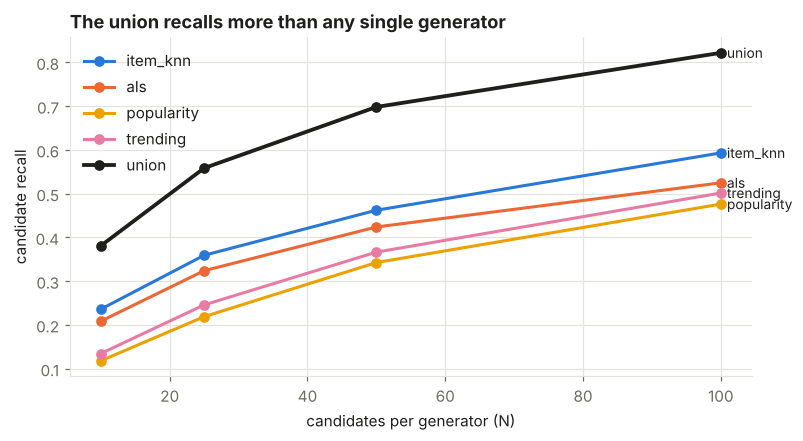

In [3]:
fig, ax = plt.subplots()
for name in list(gens) + ["union"]:
    color = model_color(name) if name != "union" else "#1f1f1e"
    ax.plot(Ns, recall_table[name], marker="o", color=color, label=name, linewidth=2.5 if name == "union" else 2)
    ax.annotate(name, (Ns[-1], recall_table[name].iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlabel("candidates per generator (N)"); ax.set_ylabel("candidate recall")
ax.set_title("The union recalls more than any single generator"); ax.legend(loc="upper left")
plt.show()

The union beats every individual generator: they find *different* relevant items. That is the whole point of combining them. We use N = 50 per generator.

## 3. Stage 2: where do the labels come from?

This is the most common place to get two-stage systems wrong.

* Labels from the **test** period are cheating.
* Labels from the **training** period are impossible. Candidates exclude seen items, so nothing in training would ever be a positive.

The fix is to **repeat the protocol inside the training period**. Fit the generators on "inner train", generate candidates for the users active in the last `val_days`, and label each candidate 1 if the user interacted with it in that window. The ranker learns *"which candidates turn out to be relevant next week"*. At serving time we re-fit the generators on the full training period and apply the same ranker.

```
  |──────── inner train ────────|── label window ──|── test ──|
    generators fitted here        ranker labels       untouched
```

### Features

| feature | intuition |
|---|---|
| `<generator>_score`, `<generator>_rank` | how strongly each retrieval model believes in the item |
| `item_popularity`, `item_trend` | prior: popular and rising items convert more |
| `item_age_days` | freshness: new items behave differently |
| `user_activity`, `user_recency_days` | heavy, recent users are more predictable, which tells the ranker when to trust personalisation |
| `user_category_affinity` | share of the user's history in this item's category |

In [4]:
two_stage = TwoStageRecommender(n_candidates=50, verbose=True).fit(
    data.X_train, train_events=data.train_events, user_map=data.user_map,
    item_map=data.item_map, item_categories=item_categories)
pd.Series(two_stage.train_report_)

Stage 1: generators on inner train (2015-06-17 cutoff)
  fitting generator: item_knn
  fitting generator: als


  fitting generator: popularity
  fitting generator: trending
Stage 2: ranker on {'val_users': 694, 'candidate_recall': 0.6484410302756439, 'ranker_rows': 74540, 'ranker_users': 631, 'positive_rate': 0.01925140863965656}


Stage 3: re-fitting generators on the full training period
  fitting generator: item_knn
  fitting generator: als


  fitting generator: popularity
  fitting generator: trending


val_users             694.000000
candidate_recall        0.648441
ranker_rows         74540.000000
ranker_users          631.000000
positive_rate           0.019251
dtype: float64

Note `positive_rate`: only a few percent of candidates are positives. That is normal. Also note that **users with no positive candidate are dropped** from ranker training. They contain no information about *ordering*, only about retrieval failures.

## 4. Inspect one user's reranked list

In [5]:
user = int(data.ground_truth.users[0])
c = two_stage.candidates([user]).sort_values("ranker_score", ascending=False)
c["relevant (test)"] = c["item"].isin(data.ground_truth.relevant[user])
cols = ["item", "ranker_score", "relevant (test)"] + [f"{g}_rank" for g in two_stage.generators] + ["item_popularity"]
c[cols].head(10).round(3)

,item,ranker_score,relevant (test),item_knn_rank,als_rank,popularity_rank,trending_rank,item_popularity
115,966,0.413,True,1,3,50,30,3.638
118,980,0.128,False,24,50,50,50,2.303
0,2,0.092,False,0,7,26,35,4.533
35,118,0.053,False,2,21,50,50,3.714
119,986,0.049,False,42,50,50,50,2.079
90,679,0.048,False,13,33,50,50,3.296
83,563,0.047,False,29,14,50,50,2.079
81,541,0.041,False,35,50,50,50,2.079
33,116,0.040,False,11,36,50,50,3.219
48,178,0.040,False,3,13,50,50,3.584


## 5. Test-set comparison

,precision@10,recall@10,hit_rate@10,map@10,ndcg@10,mrr,coverage,novelty,n_users
two_stage,0.0707,0.2665,0.5072,0.1338,0.2012,0.2642,0.3295,4.8544,627
item_knn,0.0668,0.2566,0.4625,0.1313,0.1929,0.2440,0.4031,5.6847,627
als,0.0608,0.2319,0.4322,0.1143,0.1723,0.2223,0.3818,5.6103,627
trending,0.0341,0.1262,0.2855,0.0376,0.0738,0.0867,0.0203,3.4042,627
popularity,0.0293,0.1037,0.2568,0.0340,0.0664,0.0927,0.0194,3.2515,627


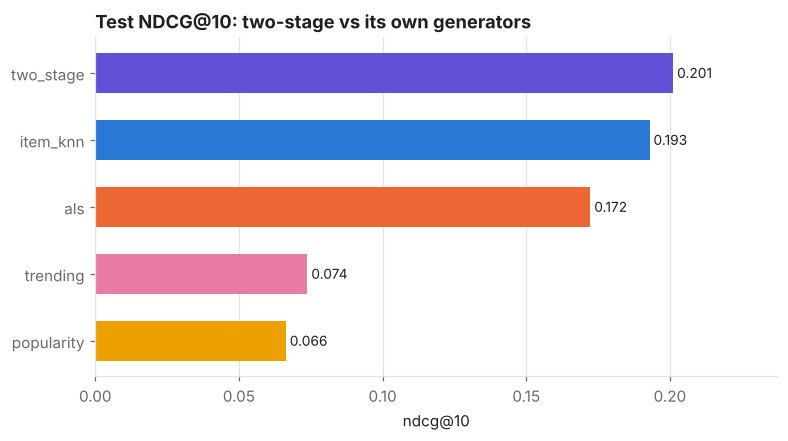

In [6]:
singles = {
    "popularity": PopularityRecommender().fit(data.X_train),
    "trending": TrendingRecommender().fit(data.X_train, train_events=data.train_events, item_map=data.item_map),
    "item_knn": ItemKNNRecommender().fit(data.X_train),
    "als": ALSRecommender().fit(data.X_train),
}
board = evaluate_many({**singles, "two_stage": two_stage}, data.X_train, data.ground_truth)
display(board.round(4))
bar_leaderboard(board, "ndcg@10", title="Test NDCG@10: two-stage vs its own generators")
plt.show()

## 6. What does the ranker rely on?

**Permutation importance**: shuffle one feature and measure how much ranker quality drops. We compute it on a held-out set of *users* from the ranker's training frame, so that we measure generalisation rather than memorisation.

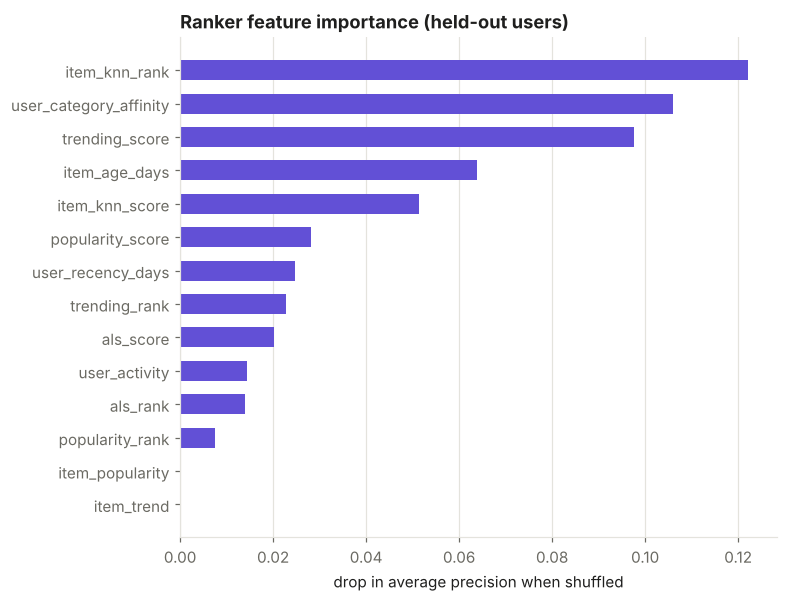

In [7]:
from sklearn.inspection import permutation_importance

frame = two_stage.ranker_train_frame_
rng = np.random.default_rng(0)
holdout_users = rng.choice(frame["user"].unique(), size=max(1, frame["user"].nunique() // 5), replace=False)
hold = frame[frame["user"].isin(holdout_users)]
imp = permutation_importance(two_stage.ranker_, hold[two_stage.feature_names_], hold["label"],
                             scoring="average_precision", n_repeats=3, random_state=0)
imp = pd.Series(imp.importances_mean, index=two_stage.feature_names_).sort_values()

fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1))
ax.barh(imp.index, imp.values, color=PALETTE[6], height=0.6)
ax.set_xlabel("drop in average precision when shuffled"); ax.grid(axis="y", visible=False)
ax.set_title("Ranker feature importance (held-out users)")
plt.show()

> **Principal DS note.** The ranker is often where the biggest *business* wins come from. Not because of the algorithm, but because it is where you inject business knowledge: margin, stock levels, diversity rules, freshness. Keep the generators simple and the features rich.

## Key takeaways

* Retrieval sets the **ceiling** (candidate recall), and ranking decides the **order**.
* Combine generators that fail in different ways.
* Ranker labels must come from a **time window inside training**, never from test.
* Permutation importance on held-out users tells you what the ranker actually uses.

## Exercises

1. **(Easy)** Drop the `popularity` and `trending` generators. What happens to candidate recall and to final NDCG?
2. **(Medium)** Add a feature: *the number of times the user interacted with this item's category in their last session*. Does it help?
3. **(Medium)** Swap the pointwise `HistGradientBoostingClassifier` for a **listwise** LambdaMART: `lightgbm.LGBMRanker(objective="lambdarank")` with `group=` sizes per user. Pass it via `TwoStageRecommender(ranker=...)` (you will need a small adapter, since `predict_proba` is used).
4. **(Stretch)** Train on **several** label windows (weeks −3, −2 and −1) instead of one. Does more training data for the ranker help, or does drift hurt?